# Understanding Wasserstein GAN with Gradient Penalty (WGAN-GP)

While standard GANs and DCGANs rely on a binary classification game (Real vs. Fake), **WGAN-GP** completely rewrites the mathematical rules of the game to achieve incredible training stability and eliminate mode collapse.

### The Mathematical Intuition: Earth Mover's Distance
In standard GANs, we measure how much the real and fake data distributions overlap. If they don't overlap at all (which is very common early in training), the math breaks down, providing no useful directional feedback to the Generator (the *Vanishing Gradient* problem).

WGAN introduces the **Wasserstein Distance** (often called the Earth Mover's Distance). Imagine the real and fake data distributions as two separate piles of dirt. The Wasserstein distance is the minimum cost (amount of dirt $\times$ distance moved) required to physically shovel and reshape the "fake" dirt pile until it perfectly matches the "real" dirt pile. Because of this approach, even if the piles are infinitely far apart, the Generator always receives a smooth, meaningful gradient pointing exactly where to push the data.

### Key Differences from Standard GAN (DCGAN)
* **The Critic, Not a Discriminator:** The evaluating network no longer guesses probabilities between $0$ and $1$. It outputs a raw, unconstrained score (e.g., $-20$ for fake, $+50$ for real) indicating the level of "realness." The `Sigmoid` activation is completely removed from the final layer.
* **Gradient Penalty (GP):** To make the Earth Mover's math work, the Critic's scoring function must be extremely smooth (formally known as 1-Lipschitz continuous). We enforce this by penalizing the Critic if the gradient (slope) of its scores deviates from $1$ along the paths connecting real and fake images.
* **No Batch Normalization in the Critic:** Batch Normalization creates mathematical dependencies between images in the same batch. This ruins the individual Gradient Penalty calculation. Therefore, `BatchNorm2d` is completely removed from the Critic.
* **Asymmetric Training Schedule:** In standard GANs, a Discriminator that is too good halts training. In WGAN-GP, a better Critic provides *better* gradients. Therefore, the Critic is typically trained $5$ times for every $1$ update of the Generator.

### Common Use Cases
Because of its robust stability and immunity to mode collapse, WGAN-GP is the go-to architecture for difficult generative tasks:
* **High-Diversity Image Generation:** Generating highly varied datasets (like diverse human faces or landscapes) where a standard GAN would collapse into generating a single, average image.
* **Medical Data Augmentation:** Generating synthetic MRI, CT, or X-ray scans to expand training datasets, requiring absolute certainty that the network is generating diverse, unique patients rather than just memorizing one.
* **Sequential/Discrete Data:** The continuous, smooth loss function makes WGANs much easier to adapt for generating time-series data, audio, or text, which are notoriously difficult for standard GANs.

In [1]:
import torch
from torch import nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import torch_directml

### WGAN-GP Hyperparameters & Setup

Key changes in configuration compared to standard DCGAN:

* **`LEARNING_RATE = 1e-4`**: Slightly lower learning rate than standard DCGAN ($2 \times 10^{-4}$) to ensure smooth gradient updates and prevent instability.
* **`BETA1 = 0.0` & `BETA2 = 0.9`**: Adam optimizer momentum (`beta1`) is explicitly set to `0.0` (no momentum). Momentum in Adam causes severe oscillations in the non-stationary loss landscape of Wasserstein distance.
* **`CRITIC_ITERATIONS = 5`**: Asymmetric training schedule. For every single update of the Generator, the Critic is trained $5$ times. A stronger Critic provides a reliable, smooth Earth Mover's gradient for the Generator.
* **`LAMBDA_GP = 10`**: The gradient penalty coefficient ($\lambda$). It scales the penalty applied when the Critic's gradient norm strays from $1$. $10$ is the standard value proven to work across most domains.
* **`BATCH_SIZE = 64`**: Reduced from $128$ to accommodate the extra VRAM required for tracking gradients during the Gradient Penalty calculation.

In [2]:
BATCH_SIZE = 64
IMAGE_SIZE = 64
CHANNELS = 3
LATENT_DIM = 100

LEARNING_RATE = 1e-4
BETA1 = 0.0
BETA2 = 0.9
CRITIC_ITERATIONS = 5
LAMBDA_GP = 10
EPOCHS = 25

GEN_FEATURES = 64
DISC_FEATURES = 64

DEVICE = torch_directml.device()

In [3]:
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = torchvision.datasets.ImageFolder(root='data/intel-image/train', transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

In [4]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.main = nn.Sequential(
            # ---Block 1: From noise (1x1) to small image (4x4)---
            nn.ConvTranspose2d(in_channels=LATENT_DIM, out_channels=GEN_FEATURES * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES * 8),
            nn.ReLU(inplace=True),
            # Output: [512, 4, 4]

            # ---Block 2: From 4x4 to 8x8---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES * 8, out_channels=GEN_FEATURES * 4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES * 4),
            nn.ReLU(inplace=True),
            # Output: [256, 8, 8]

            # ---Block 3: From 8x8 to 16x16---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES * 4, out_channels=GEN_FEATURES * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES * 2),
            nn.ReLU(inplace=True),
            # Output: [128, 16, 16]

            # ---Block 4: From 16x16 to 32x32---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES * 2, out_channels=GEN_FEATURES, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=GEN_FEATURES),
            nn.ReLU(inplace=True),
            # Output: [64, 32, 32]

            # ---Block 5: From 32x32 to 64x64---
            nn.ConvTranspose2d(in_channels=GEN_FEATURES, out_channels=CHANNELS, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
            # Output: [3, 64, 64]
        )

    def forward(self, x):
        return self.main(x)


### WGAN-GP Critic Architecture

Key architectural differences from the DCGAN Discriminator:

* **No `BatchNorm2d` Layers:** Batch Normalization introduces dependencies across samples within the same batch. This breaks the mathematical foundation of Gradient Penalty, which evaluates gradients on individual image samples.
* **No Final Activation (`Sigmoid` Removed):** The Critic does not classify images into probabilities $[0, 1]$. It outputs raw, unbounded real-valued scores ($-\infty, +\infty$) representing the "realness" of each image.
* **1D Output Vector (`.view(-1)`):** Flattens the final spatial dimensions into a single scalar score per sample in the batch.

In [5]:
class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(CHANNELS, DISC_FEATURES, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(DISC_FEATURES, DISC_FEATURES * 2, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(DISC_FEATURES * 2, DISC_FEATURES * 4, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(DISC_FEATURES * 4, DISC_FEATURES * 8, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(DISC_FEATURES * 8, 1, 4, 1, 0, bias=False),
        )

    def forward(self, x):
        return self.main(x).view(-1)

In [6]:
netG = Generator().to(DEVICE)
netC = Critic().to(DEVICE)

In [7]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

netG.apply(weights_init)
netC.apply(weights_init)

optimizerG = torch.optim.Adam(netG.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
optimizerC = torch.optim.Adam(netC.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

### Gradient Penalty Function (`compute_gradient_penalty`)

To enforce the 1-Lipschitz continuity constraint required by the Wasserstein distance, we penalize the Critic if its gradient norm deviates from $1$:

* **Random Interpolation (`alpha`):** Creates hybrid images along a straight line connecting real and fake samples:  
  $$\hat{x} = \alpha x_{real} + (1 - \alpha) x_{fake}$$
* **`requires_grad_(True)`:** Explicitly tells PyTorch to track operations on the interpolated images so we can compute derivatives with respect to input pixels.
* **`torch.autograd.grad`:** Computes the gradient of the Critic's scores ($\nabla_{\hat{x}} D(\hat{x})$) relative to the hybrid input images ($\hat{x}$).
* **Gradient Norm ($\ell_2$-norm):** Flattens the gradient tensor and calculates its magnitude per image across spatial and channel dimensions (`gradients.norm(2, dim=1)`).
* **Penalty Calculation:** Penalizes squared deviations from $1$:  
  $$\text{GP} = \mathbb{E}\left[(\|\nabla_{\hat{x}} D(\hat{x})\|_2 - 1)^2\right]$$

In [8]:
def compute_gradient_penalty(netC, real_samples, fake_samples):
    alpha = torch.rand((real_samples.size(0), 1, 1, 1), device=DEVICE)
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    d_interpolates = netC(interpolates)
    fake = torch.ones((real_samples.shape[0],), device=DEVICE)

    gradients = torch.autograd.grad(
        outputs=d_interpolates,
        inputs=interpolates,
        grad_outputs=fake,
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]

    gradients = gradients.view(gradients.size(0), -1)
    gradient_norm = gradients.norm(2, dim=1)

    gradient_penalty = ((gradient_norm - 1) ** 2).mean()
    return gradient_penalty

### WGAN-GP Training Loop & Loss Functions

Key mechanics of the training loop:

* **Asymmetric Updating (`CRITIC_ITERATIONS`):** The Critic inner loop runs $5$ times per single Generator update. This ensures the Critic stays near-optimal, providing accurate Wasserstein gradient estimates.
* **Critic Loss Formulation:**
  $$\mathcal{L}_C = \mathbb{E}[\tilde{x}] - \mathbb{E}[x] + \lambda \cdot \text{GP}$$
  Where $\tilde{x}$ are fake images and $x$ are real images. Maximizing real scores while minimizing fake scores translates to minimizing $\mathbb{E}[\tilde{x}] - \mathbb{E}[x]$.
* **Generator Loss Formulation:**
  $$\mathcal{L}_G = -\mathbb{E}[D(\tilde{x})]$$
  The Generator optimizes purely to maximize the raw Critic score assigned to generated samples.
* **Wasserstein Distance Tracking:**
  $$W(p_r, p_g) \approx \mathbb{E}[D(x)] - \mathbb{E}[D(\tilde{x})]$$
  Tracks convergence quality. Unlike standard GAN cross-entropy loss (which fluctuates endlessly), the estimated Wasserstein distance provides a meaningful metric that correlates directly with visual image quality.

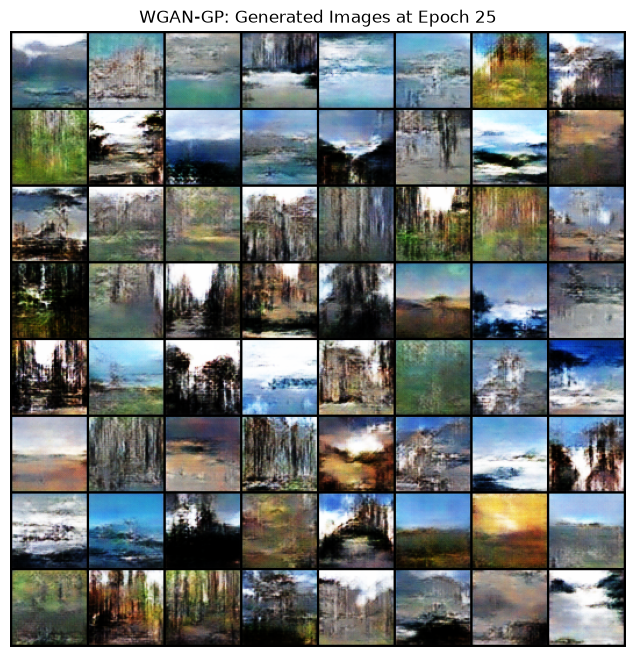

In [9]:
from IPython.display import clear_output

fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=DEVICE)

Wasserstein_distances = []

for epoch in range(EPOCHS):
    for i, data in enumerate(dataloader, 0):
        real_images = data[0].to(DEVICE)
        cur_batch_size = real_images.size(0)

        # --- Phase 1: Critic Training ---
        for _ in range(CRITIC_ITERATIONS):
            netC.zero_grad()
            real_critic_score = netC(real_images)

            noise = torch.randn(cur_batch_size, LATENT_DIM, 1, 1, device=DEVICE)
            fake_images = netG(noise)
            fake_critic_score = netC(fake_images.detach())

            gp = compute_gradient_penalty(netC, real_images, fake_images.detach())

            loss_C = fake_critic_score.mean() - real_critic_score.mean() + LAMBDA_GP * gp
            loss_C.backward()
            optimizerC.step()

        # --- Phase 2: Generator Training ---
        netG.zero_grad()

        noise = torch.randn(cur_batch_size, LATENT_DIM, 1, 1, device=DEVICE)
        fake_images = netG(noise)

        fake_critic_score = netC(fake_images)

        loss_G = -fake_critic_score.mean()
        loss_G.backward()
        optimizerG.step()

        w_dist = (real_critic_score.mean() - fake_critic_score.mean()).item()
        Wasserstein_distances.append(w_dist)

        if i % 100 == 0:
            print(f"[{epoch}/{EPOCHS}][{i}/{len(dataloader)}] "
                  f"Critic Loss: {loss_C.item():.4f} | Generator Loss: {loss_G.item():.4f} | "
                  f"Wasserstein Distance: {w_dist:.4f}")

    with torch.no_grad():
        fake_test = netG(fixed_noise).detach().cpu()

    clear_output(wait=True)
    plt.figure(figsize=(8, 8))
    plt.axis("off")
    plt.title(f'WGAN-GP: Generated Images at Epoch {epoch + 1}')
    plt.imshow(np.transpose(torchvision.utils.make_grid(fake_test, padding=2, normalize=True), (1, 2, 0)))
    plt.show()

torch.save(netG.state_dict(), 'wgangp_intel.pth')
            

### Latent Space Walk (Linear Interpolation)

Evaluating generator representation through smooth transitions across the latent manifold:

* **Evaluation Mode (`netG.eval()`):** Disables training-specific behaviors like active `BatchNorm` running mean/variance updates to ensure deterministic evaluation outputs.
* **Linear Interpolation (SLERP / LERPING):** Moves in straight steps between fixed anchor points in the latent space $z$:
  $$z_{\text{interp}} = (1 - \alpha) \cdot z_{\text{start}} + \alpha \cdot z_{\text{end}}, \quad \alpha \in [0, 1]$$
* **Manifold Continuity Check:** Smooth transitions between visual concepts (e.g., mountains smoothly evolving into forests or urban structures) confirm that the latent space is continuous and structured, proving the network did not suffer from mode collapse or simple memorization.

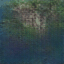

In [11]:
from PIL import Image
from IPython.display import display, Image as IPyImage

netG.eval()

NUM_ANCHORS = 5
STEPS_PER_TRANSITION = 30
FPS = 15

anchors = torch.randn(NUM_ANCHORS, LATENT_DIM, 1, 1, device=DEVICE)
frames = []

with torch.no_grad():
    for i in range(NUM_ANCHORS - 1):
        start_vector = anchors[i]
        end_vector = anchors[i + 1]

        for alpha in np.linspace(0, 1, STEPS_PER_TRANSITION):
            interpolated_vector = (1 - alpha) * start_vector + alpha * end_vector
            interpolated_vector = interpolated_vector.unsqueeze(0)

            generated_img = netG(interpolated_vector)

            img_tensor = generated_img.squeeze(0).cpu()
            img_tensor = (img_tensor + 1) / 2.0
            img_tensor = torch.clamp(img_tensor, 0, 1)

            img_np = img_tensor.permute(1, 2, 0).numpy()
            img_np = (img_np * 255).astype(np.uint8)

            frames.append(Image.fromarray(img_np))

gif_path = 'wgangp_latent_walk.gif'

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=int(1000 / FPS),
    loop=0
)

display(IPyImage(filename=gif_path))
